# 06逻辑回归：实现

epoch 0, loss = 0.6931
epoch 1000, loss = 0.3428
epoch 2000, loss = 0.3428
epoch 3000, loss = 0.3428
epoch 4000, loss = 0.3428
epoch 5000, loss = 0.3428

训练集准确率：0.865


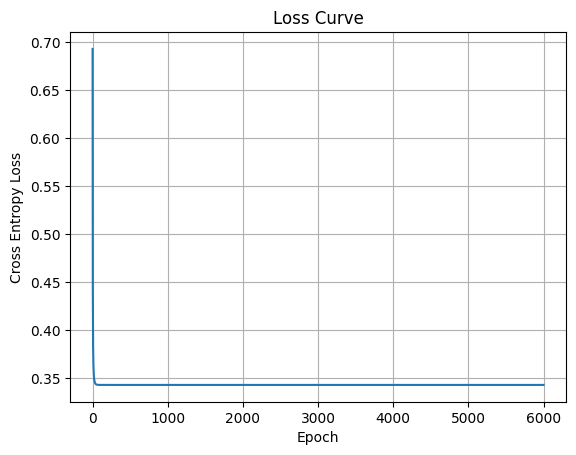

In [1]:
# Numpy(带Loss曲线记录)
import numpy as np
import matplotlib.pyplot as plt

# Day4 Sigmoid
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# 前向传播，输出预测概率
def predict_proba(X, w, b):
    z = X @ w + b
    return sigmoid(z)

# Day5 交叉熵损失
def cross_entropy(y, p):
    n = len(y)
    eps = 1e-8
    return -1 / n * np.sum(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

# Day5 梯度下降训练
def fit_logistic(X, y, lr=0.5, epochs=6000):
    n_sample, n_feat = X.shape
    w = np.zeros(n_feat)
    b = 0.0
    loss_history = []

    for epoch in range(epochs):
        p = predict_proba(X, w, b)
        dw = (1 / n_sample) * X.T @ (p - y)
        db = (1 / n_sample) * np.sum(p - y)
        # 更新参数
        w -= lr * dw
        b -= lr * db
        loss = cross_entropy(y, p)
        loss_history.append(loss)

        if epoch % 1000 == 0:
            print(f"epoch {epoch}, loss = {loss:.4f}")
    return w, b, loss_history

# 概率转类别，阈值默认 0.5
def predict(X, w, b, threshold=0.5):
    p = predict_proba(X, w, b)
    return (p >= threshold).astype(int)

# 生成测试数据集
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0, random_state=42)

# 训练模型
w, b, loss_hist = fit_logistic(X, y, lr=0.8, epochs=6000)
y_pred = predict(X, w, b)
acc = np.mean(y_pred == y)
print(f"\n训练集准确率：{acc:.3f}")

# 绘制损失下降曲线
plt.plot(loss_hist)
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Loss Curve")
plt.grid()
plt.show()

In [2]:
# sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# sklearn 默认开启 L2 正则化（Day8 内容）
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)
y_pred_p = lr_model.predict_proba(X_test)

print("测试集准确率：", accuracy_score(y_test, y_pred))
print("权重 w：", lr_model.coef_)
print("偏置 b：", lr_model.intercept_)
print(classification_report(y_test, y_pred))

测试集准确率： 0.8
权重 w： [[ 2.01388452 -0.18643299]]
偏置 b： [-0.10596372]
              precision    recall  f1-score   support

           0       0.82      0.74      0.78        19
           1       0.78      0.86      0.82        21

    accuracy                           0.80        40
   macro avg       0.80      0.80      0.80        40
weighted avg       0.80      0.80      0.80        40



## 配套练习
1. 修改学习率，观察 loss 曲线收敛、震荡情况
2. 调整分类阈值（0.3 / 0.7），理解阈值对正负样本判定的影响
3. 绘制样本点 + 决策边界直线
4. 对比手写版本与 sklearn 版本预测结果差异
> Day6 小结：将 Day4、Day5 的数学公式翻译成可运行代码，完成二分类任务